# BADMET real-data example: three measurements and their joint posterior

This notebook takes one observation from the paper's real sample and compares four inference results: three single-proxy measurements and their joint posterior. The catalog reference mass is shown only as an external benchmark; it is never included in the likelihood.

| Measurement | BADMET method | Role |
|---|---|---|
| Variability timescale $\tau$ | `add_tau` | Includes the finite-baseline/cadence correction |
| X-ray luminosity $L_X$ | `add_param` | Observable predicted as a function of mass |
| Normalized excess variance $\sigma^2_{\rm NXV}$ | `add_Mparam` | Relation that directly predicts mass |

The final panel compares the three individual posteriors with the joint constraint $p(M_{\rm BH}\mid\tau,L_X,\sigma^2_{\rm NXV})$.

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "badmet" / "estimator.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from BADMET or one of its subdirectories.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import autograd.numpy as anp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from badmet import MassEstimator

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Select one observation from the paper sample

We use **NGC 7314**, observation **0790650101**. The row is read from the same cached real-data table used by `Paper/PaperPlot.ipynb`; no values are retyped by hand.

In [2]:
data = pd.read_pickle(ROOT / "Paper" / "data" / "dfx_MassEstimated_1.pkl")
match = data[(data["src_name"] == "NGC 7314") & (data["obsid"].astype(str) == "0790650101")]
if len(match) != 1:
    raise RuntimeError(f"Expected one matching observation, found {len(match)}.")
source = match.iloc[0]

inputs = pd.DataFrame({
    "measurement": ["Variability timescale", "X-ray luminosity", "Normalized excess variance"],
    "value": [source.log_tau_mle, source.lumin, source.log_sigma2_NXV],
    "measurement error": [np.nan, source.lumin_err, source.log_sigma2_NXV_ERR],
    "unit / scale": ["log10(tau)", "log10(erg/s)", "log10(sigma_NXV^2)"],
})
inputs.style.format({"value": "{:.4f}", "measurement error": lambda x: "—" if pd.isna(x) else f"{x:.4f}"})

,measurement,value,measurement error,unit / scale
0,Variability timescale,3.2401,—,log10(tau)
1,X-ray luminosity,42.2530,0.0017,log10(erg/s)
2,Normalized excess variance,-1.3098,0.0081,log10(sigma_NXV^2)


The timescale likelihood additionally uses this observation's baseline, cadence, and source redshift. Its uncertainty comes from the correction lookup plus the adopted 0.40 dex relation scatter.

In [3]:
pd.Series({
    "baseline": source.baseline,
    "number of cadences": source.ncadence,
    "redshift": source.redshift,
}, name="timescale context")

baseline              63400.000000
number of cadences      635.000000
redshift                  0.004607
Name: timescale context, dtype: float64

## 2. Define the three empirical relations

These are the same relations and intrinsic scatters used in the real-data section of `PaperPlot.ipynb`.

In [4]:
def mass_from_nxv(log_sigma2_nxv):
    return -0.94 * (log_sigma2_nxv - anp.log10(0.005)) + 7.41

def expected_lx(log_mass):
    return 0.89 * (log_mass - 8.0) - 0.16 + 44.0

def expected_log_tau(log_mass, redshift):
    return 1.28 * log_mass - 4.37 + anp.log10(1.0 + redshift)

## 3. Fit each proxy, then combine all three

The helper below contains only the three proxy likelihoods used for the paper prediction. Each is fitted separately, then all three are added to one estimator for the joint result.

In [5]:
def add_measurement(estimator, method, row):
    if method == "Timescale":
        estimator.add_tau(
            row.log_tau_mle, row.baseline, row.ncadence,
            expected_log_tau, 0.40, args=[row.redshift], args_err=[0.0],
        )
    elif method == "X-ray luminosity":
        estimator.add_param(row.lumin, row.lumin_err, expected_lx, 0.70)
    elif method == "Excess variance":
        estimator.add_Mparam(
            mass_from_nxv, 0.70,
            args=[row.log_sigma2_NXV], args_err=[row.log_sigma2_NXV_ERR],
        )
    else:
        raise ValueError(f"Unknown method: {method}")

methods = ["Timescale", "X-ray luminosity", "Excess variance"]
colors = {
    "Timescale": "#E45756",
    "X-ray luminosity": "#F2CF5B", "Excess variance": "#72B7B2",
    "Joint (three proxies)": "#6F4E7C", "Reference mass": "#4C78A8",
}

In [6]:
np.random.seed(42)
samples = {}
for method in methods:
    estimator = MassEstimator()
    add_measurement(estimator, method, source)
    samples[method] = estimator.estimate(
        initial=np.array([source.LOGMBH]), nwalkers=24, nsteps=1200, pool_size=1
    )[:, 0]

joint = MassEstimator()
for method in methods:
    add_measurement(joint, method, source)
samples["Joint (three proxies)"] = joint.estimate(
    initial=np.array([source.LOGMBH]), nwalkers=24, nsteps=1200, pool_size=1
)[:, 0]

## 4. Compare the four posteriors

Each row reports the median and central 68% credible interval. The plot makes the relative constraining power and the joint result visible at a glance.

In [7]:
summary = []
for label, chain in samples.items():
    lo, med, hi = np.percentile(chain, [16, 50, 84])
    summary.append((label, med, med-lo, hi-med))
summary = pd.DataFrame(summary, columns=["method", "median", "-1 sigma", "+1 sigma"])
summary.style.format({"median": "{:.3f}", "-1 sigma": "{:.3f}", "+1 sigma": "{:.3f}"})

,method,median,-1 sigma,+1 sigma
0,Timescale,6.176,0.457,2.651
1,X-ray luminosity,6.192,0.777,0.814
2,Excess variance,6.511,0.718,0.673
3,Joint (three proxies),6.100,0.296,0.328


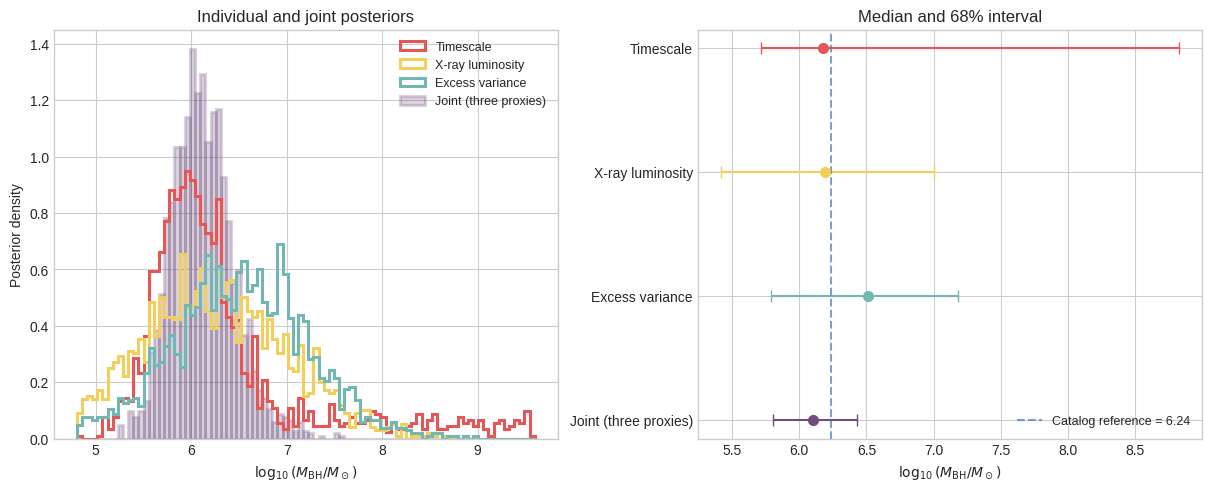

In [8]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
bins = np.linspace(4.8, 9.6, 90)
for label in methods:
    ax.hist(samples[label], bins=bins, density=True, histtype="step", lw=2.2,
            color=colors[label], label=label)
ax.hist(samples["Joint (three proxies)"], bins=bins, density=True, color=colors["Joint (three proxies)"],
        alpha=0.25, edgecolor=colors["Joint (three proxies)"], lw=2.2, label="Joint (three proxies)")
ax.set(xlabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$", ylabel="Posterior density",
       title="Individual and joint posteriors")
ax.legend(frameon=False, fontsize=9)

plot_summary = summary.iloc[::-1].reset_index(drop=True)
for y, row in plot_summary.iterrows():
    ax2.errorbar(row["median"], y, xerr=[[row["-1 sigma"]], [row["+1 sigma"]]],
                 fmt="o", ms=7, capsize=4, color=colors[row["method"]])
ax2.set_yticks(range(len(plot_summary)), plot_summary["method"])
ax2.axvline(source.LOGMBH, color=colors["Reference mass"], ls="--", alpha=0.7,
            label=f"Catalog reference = {source.LOGMBH:.2f}")
ax2.set(xlabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$", title="Median and 68% interval")
ax2.legend(frameon=False, fontsize=9, loc="lower right")
plt.show()

## Interpretation

- The catalog reference mass is plotted only for comparison and contributes nothing to any posterior.
- The three proxy posteriors are broad because the paper adopts 0.40–0.70 dex intrinsic scatter.
- `add_tau` also propagates the observing-window correction uncertainty.
- The joint result reproduces the structure of the paper's proxy-only prediction (`LOGMBH_6`): $\tau$, $L_X$, and $\sigma^2_{\rm NXV}$ enter one likelihood.

> This short run is for API demonstration. Production work should use longer chains and explicit convergence checks.